# Reverse BBP — pouring π out of its own motion

BBP answers *what is the digit at position n*. It jumps. This notebook runs the same
machinery forward and **pours digits out in order**, from a formula that you grow to
whatever length you ask for.

### What the formula is

Long-divide `1/d` in base 16 and the remainders repeat. So every reciprocal is a **finite
tape**: a short transient, then a cycle that runs forever. BBP's lane denominators are
`d = 8k + j` for `j ∈ {1, 4, 5, 6}` with weights `+4, −2, −1, −1`.

Substituting each tape into the BBP series and collecting powers of 16 gives

$$\pi - 4 \;=\; \sum_{n\ge 0} T_n \, 16^{-(n+1)},
\qquad
T_n \;=\; \sum_j c_j \sum_{k=0}^{n} \mathrm{Tape}[k,j]\,[\,n-k\,]$$

`T_n` is an **anti-diagonal** of a triangular table of tapes. Nothing but lookup and add.

That is a base-16 representation of π whose digits are the `T_n`. They are not in 0..15 —
they are integers of size about `n`, so the representation is **redundant**. Ordinary π is
that representation normalised by carry.

| | |
|---|---|
| `T_n` | local, parallel, pure table lookup |
| carry | the only non-local step |

One operation underneath all of it, at two moduli:

$$16x = M q + x' \qquad\begin{cases}M = d = 8k+j & \text{a lane: } q \text{ is a tape digit}\\ M = 1 & \text{the reader: } q \text{ is a digit of } \pi\end{cases}$$

---
## 0 · How many digits?

In [ ]:
# Hexadecimal digits of pi to produce.
# Run this cell and type a number, or just set N below and skip the prompt.

try:
    _r = input('How many hex digits of pi? [256] ').strip()
    N = int(_r) if _r else 256
except Exception:
    N = 256

print(f'N = {N} hexadecimal digits')

---
## 1 · The machine

Everything below is this one cell. `tape(d)` is long division until the remainder repeats.
`Formula` is the grown table. `column(n)` is `T_n`. `pour` normalises.

In [2]:
import math, time

WEIGHTS = {1: 4, 4: -2, 5: -1, 6: -1}   # the classical BBP lane weights; they sum to 0
HEX = '0123456789ABCDEF'


def tape(d):
    """Base-16 digits of 1/d as (transient, cycle). The orbit always closes."""
    if d == 1:
        return [], [0]                      # 1/1 is an integer; it never reaches the fraction
    seen, qs = {}, []
    r, e = 1 % d, 0
    while r not in seen:
        seen[r] = e
        q, r = divmod(16 * r, d)            # 16*r = d*q + r'   <- the one operation
        qs.append(q)
        e += 1
    s = seen[r]
    return qs[:s], qs[s:]


class Formula:
    """The grown formula: one tape per lane for k = 0..depth."""

    def __init__(self, depth):
        self.depth = depth
        self.rows = {(k, j): tape(8 * k + j)
                     for k in range(depth + 1) for j in WEIGHTS}

    def digit(self, k, j, m):
        t, c = self.rows[(k, j)]
        return t[m] if m < len(t) else c[(m - len(t)) % len(c)]

    def column(self, n):
        """T_n: the anti-diagonal sum. The whole transformation lives here."""
        tot = 0
        for j, c in WEIGHTS.items():
            s = 0
            for k in range(n + 1):
                s += self.digit(k, j, n - k)
            tot += c * s
        return tot

    def size(self):
        states = sum(len(t) + len(c) for t, c in self.rows.values())
        return len(self.rows), states, max(len(c) for _, c in self.rows.values())


def guard_for(n_digits):
    """Extra columns so the carry from beyond the window cannot reach digit n_digits."""
    return 12 + max(1, math.ceil(math.log(max(n_digits, 2), 16)))


def pour(n_digits, formula=None, verbose=True):
    """Normalise the redundant representation into ordinary hex digits of pi."""
    M = n_digits + guard_for(n_digits)
    f = formula or Formula(M)
    X = 0
    t0 = time.time()
    for n in range(M + 1):
        X = X * 16 + f.column(n)            # Horner on the redundant digits
    Y = 4 * 16 ** (M + 1) + X               # pi = 4 + sum T_n 16^-(n+1)
    s = format(Y, 'X').rjust(M + 2, '0')
    if verbose:
        print(f'poured {n_digits} digits in {time.time()-t0:.2f}s')
    return s[0] + '.' + s[1:1 + n_digits]

print('machine defined')

machine defined


---
## 2 · Grow the formula

Growing it to `N` digits means materialising rows `k = 0..N`. Each row is finite because
the long division closes. Nothing here has seen a digit of π.

In [3]:
t0 = time.time()
F = Formula(N + guard_for(N))
rows, states, longest = F.size()
print(f'grown in {time.time()-t0:.2f}s')
print(f'  tapes          : {rows}')
print(f'  stored digits  : {states}')
print(f'  longest cycle  : {longest}')
print(f'  bytes (approx) : {states}')

grown in 0.02s
  tapes          : 1084
  stored digits  : 91530
  longest cycle  : 535
  bytes (approx) : 91530


---
## 3 · Look at the formula

The first rows of the table. `j` is the lane, `d = 8k+j` the modulus, and the tape is the
base-16 expansion of `1/d`: a transient in brackets, then the repeating cycle.

In [4]:
def show_tape(k, j, width=18):
    d = 8 * k + j
    t, c = F.rows[(k, j)]
    body = ''.join(HEX[x] for x in t)
    body = (f'[{body}]' if body else '') + '(' + ''.join(HEX[x] for x in c) + ')'
    run = ''.join(HEX[F.digit(k, j, m)] for m in range(width))
    return f'  k={k} j={j}  d={d:4d}  w={WEIGHTS[j]:+d}   1/d = 0.{run}...   tape {body}'

for k in range(4):
    for j in WEIGHTS:
        print(show_tape(k, j))
    print()

  k=0 j=1  d=   1  w=+4   1/d = 0.000000000000000000...   tape (0)
  k=0 j=4  d=   4  w=-2   1/d = 0.400000000000000000...   tape [4](0)
  k=0 j=5  d=   5  w=-1   1/d = 0.333333333333333333...   tape (3)
  k=0 j=6  d=   6  w=-1   1/d = 0.2AAAAAAAAAAAAAAAAA...   tape [2](A)

  k=1 j=1  d=   9  w=+4   1/d = 0.1C71C71C71C71C71C7...   tape (1C7)
  k=1 j=4  d=  12  w=-2   1/d = 0.155555555555555555...   tape [1](5)
  k=1 j=5  d=  13  w=-1   1/d = 0.13B13B13B13B13B13B...   tape (13B)
  k=1 j=6  d=  14  w=-1   1/d = 0.124924924924924924...   tape [1](249)

  k=2 j=1  d=  17  w=+4   1/d = 0.0F0F0F0F0F0F0F0F0F...   tape (0F)
  k=2 j=4  d=  20  w=-2   1/d = 0.0CCCCCCCCCCCCCCCCC...   tape [0](C)
  k=2 j=5  d=  21  w=-1   1/d = 0.0C30C30C30C30C30C3...   tape (0C3)
  k=2 j=6  d=  22  w=-1   1/d = 0.0BA2E8BA2E8BA2E8BA...   tape [0](BA2E8)

  k=3 j=1  d=  25  w=+4   1/d = 0.0A3D70A3D70A3D70A3...   tape (0A3D7)
  k=3 j=4  d=  28  w=-2   1/d = 0.092492492492492492...   tape [0](924)
  k=3 j=5  d=  29  

### The anti-diagonal

`T_n` reads down-left across those rows: row `k` contributes its digit at offset `n-k`.

In [5]:
for n in range(6):
    parts = []
    for j, c in WEIGHTS.items():
        s = sum(F.digit(k, j, n - k) for k in range(n + 1))
        parts.append(f'{c:+d}*{s}')
    print(f'T_{n} = ' + ' '.join(parts) + f' = {F.column(n)}')

T_0 = +4*0 -2*4 -1*3 -1*2 = -13
T_1 = +4*1 -2*1 -1*4 -1*11 = -13
T_2 = +4*12 -2*5 -1*6 -1*12 = 20
T_3 = +4*22 -2*17 -1*26 -1*25 = 3
T_4 = +4*11 -2*26 -1*15 -1*37 = -60
T_5 = +4*37 -2*26 -1*25 -1*28 = 43


---
## 4 · Pour

The redundant digits go in; carry normalisation comes out.

In [6]:
digits = pour(N, formula=F)

# print in blocks of 64
head, frac = digits.split('.')
print(head + '.')
for i in range(0, len(frac), 64):
    print(f'  {i:6d}  {frac[i:i+64]}')

poured 256 digits in 0.04s
3.
       0  243F6A8885A308D313198A2E03707344A4093822299F31D0082EFA98EC4E6C89
      64  452821E638D01377BE5466CF34E90C6CC0AC29B7C97C50DD3F84D5B5B5470917
     128  9216D5D98979FB1BD1310BA698DFB5AC2FFD72DBD01ADFB7B8E1AFED6A267E96
     192  BA7C9045F12C7F9924A19947B3916CF70801F2E2858EFC16636920D871574E69


---
## 5 · Check it

Against an independent computation if `mpmath` is present, otherwise against a stored
prefix. The check is a check — the stream above was produced from the tapes alone.

In [7]:
KNOWN = ('243F6A8885A308D313198A2E03707344A4093822299F31D0082EFA98EC4E6C89'
         '452821E638D01377BE5466CF34E90C6CC0AC29B7C97C50DD3F84D5B5B5470917')

ok = None
try:
    from mpmath import mp, pi as MPPI
    mp.dps = int(N * 1.21) + 40
    x = MPPI; ip = int(x); fr = x - ip
    ref = []
    for _ in range(N):
        fr *= 16; d = int(fr); ref.append(HEX[d]); fr -= d
    ref = f'{ip:X}.' + ''.join(ref)
    ok = (digits == ref)
    print(f'checked all {N} digits against mpmath: {"MATCH" if ok else "MISMATCH"}')
    if not ok:
        for i, (a, b) in enumerate(zip(digits, ref)):
            if a != b:
                print('  first difference at index', i, a, b); break
except ImportError:
    m = min(N, len(KNOWN))
    ok = digits[2:2 + m] == KNOWN[:m]
    print(f'mpmath not installed; checked first {m} digits against stored prefix: '
          f'{"MATCH" if ok else "MISMATCH"}')

checked all 256 digits against mpmath: MATCH


---
## 6 · What it costs between digits

`T_n` is not small, and this is the part worth looking at. The lane weights sum to zero
(`4 − 2 − 1 − 1 = 0`), so `T_n` is a nearly driftless walk rather than a trend — and the
carry at each step is its near-exact negative.

**The digit is the small residue of a cancellation between two quantities that grow like n.**
That is the price of depth, with a number on it.

In [8]:
import statistics

m = min(N, 400)
T = [F.column(n) for n in range(m)]

print(f'{"n":>5} {"T_n":>8} {"carry":>8} {"digit":>6}')
frac_digits = digits.split('.')[1]
prev_rem = 0
for n in list(range(0, m, max(1, m // 12)))[:12]:
    d = int(frac_digits[n], 16)
    print(f'{n:>5} {T[n]:>8} {d - T[n]:>8} {frac_digits[n]:>6}')

print()
print(f'mean T_n over n<{m} : {statistics.mean(T):+.2f}')
print(f'sd   T_n            : {statistics.pstdev(T):.1f}')
print(f'max |T_n|           : {max(abs(t) for t in T)}')
print(f'sqrt(n) scale at n={m}: {22.9 * math.sqrt(m):.0f}   <- random-walk prediction')

    n      T_n    carry  digit
    0      -13       15      2
   21       62      -52      A
   42       48      -39      9
   63      243     -234      9
   84       49      -43      6
  105       93      -84      9
  126      717     -716      1
  147     -151      152      1
  168      -91      104      D
  189      676     -662      E
  210      -67       77      A
  231      286     -284      2

mean T_n over n<256 : +112.28
sd   T_n            : 261.4
max |T_n|           : 1018
sqrt(n) scale at n=256: 366   <- random-walk prediction


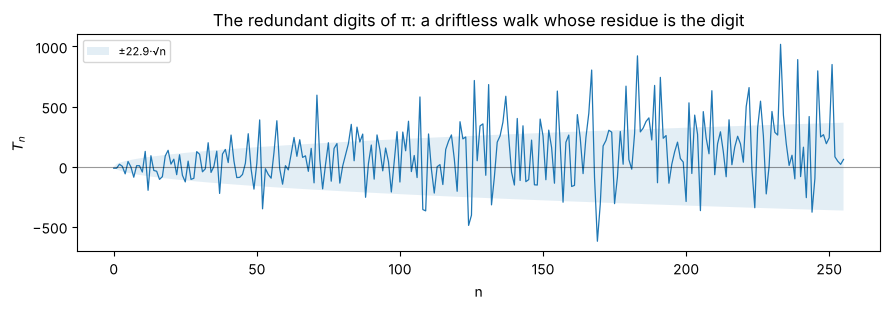

In [9]:
# Optional: see the walk.
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(range(m), T, lw=.9)
    ax.axhline(0, lw=.8, color='k', alpha=.4)
    ax.fill_between(range(m), [-22.9 * math.sqrt(n) for n in range(m)],
                    [22.9 * math.sqrt(n) for n in range(m)], alpha=.12,
                    label='±22.9·√n')
    ax.set_xlabel('n'); ax.set_ylabel('$T_n$')
    ax.set_title('The redundant digits of π: a driftless walk whose residue is the digit')
    ax.legend(loc='upper left', fontsize=8); fig.tight_layout(); plt.show()
except ImportError:
    print('matplotlib not installed; skipping the plot')

---
## What this is, and what it is not

**Is.** An exact, verified identity. π written in base 16 with redundant integer digits that
are anti-diagonal sums of reciprocal tapes, normalised by carry. The tapes are finite and
periodic — the formula is a finite object you grow, and it contains no digit of π. The
stream never calls modular exponentiation.

**Is not.** A compression or a speedup. Column `n` needs `n+1` lookups, so pouring `N`
digits is `O(N²)` work, and the stored formula grows faster than the output. Established
π algorithms are far faster. What this buys is that every step is lookup-and-add on a
finite periodic object, and the cost of depth is now a measured quantity instead of a
hidden one.

**The open edge.** `T_n` is a convolution of periodic sequences, and a convolution of
periodics is itself periodic on the lcm of the periods. The cycles here run to several
thousand. If the anti-diagonal can be folded along those periods, the growing sum collapses
into a fixed-size accumulator and the machine stops growing. That is the next thing to try,
and it is a concrete question rather than a hope.